In [3]:
from sklearn.datasets import load_digits
import numpy as np
import pandas as pd

digits = load_digits()
dir(digits)


['DESCR', 'data', 'feature_names', 'frame', 'images', 'target', 'target_names']

In [4]:
digits.images[0]
digits.data
digits.data.shape
digits.target
digits.target_names
digits.DESCR

".. _digits_dataset:\n\nOptical recognition of handwritten digits dataset\n--------------------------------------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 1797\n:Number of Attributes: 64\n:Attribute Information: 8x8 image of integer pixels in the range 0..16.\n:Missing Attribute Values: None\n:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)\n:Date: July; 1998\n\nThis is a copy of the test set of the UCI ML hand-written digits datasets\nhttps://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits\n\nThe data set contains images of hand-written digits: 10 classes where\neach class refers to a digit.\n\nPreprocessing programs made available by NIST were used to extract\nnormalized bitmaps of handwritten digits from a preprinted form. From a\ntotal of 43 people, 30 contributed to the training set and different 13\nto the test set. 32x32 bitmaps are divided into nonoverlapping blocks of\n4x4 and the number of on pixels are counted in each bl

<Figure size 640x480 with 0 Axes>

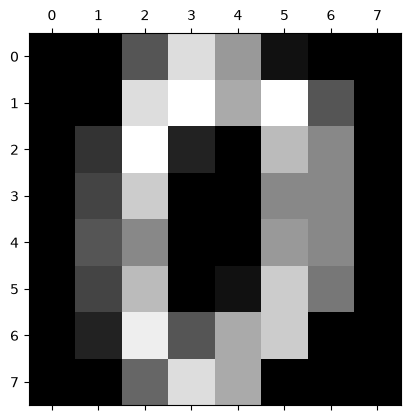

Target label: 0


In [5]:
import matplotlib.pyplot as plt

# Look at the first image and its label
plt.gray()
plt.matshow(digits.images[0])
plt.show()

print("Target label:", digits.target[0])

In [14]:
# 1. Create DataFrame from the 64 pixel features
df = pd.DataFrame(digits.data, columns=digits.feature_names)

# 2. Add the target digit column (0 to 9)
df['target'] = digits.target

# 3. Save to CSV in the same folder
df.to_csv("digits_data.csv", index=False)
print("Saved to digits_data.csv successfully!")

# 4. Inspect the DataFrame
print(f"Shape: {df.shape}")  # (1797 rows, 65 columns: 64 pixels + 1 target)
df.head()

Saved to digits_data.csv successfully!
Shape: (1797, 65)


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


**Split the  data**

In [19]:
from sklearn.model_selection import train_test_split

X= df.drop(columns="target", axis='columns')
y= df["target"]

X_train,X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)
print("Training samples:", len(X_train))  # 1437
print("Testing samples: ", len(X_test))   # 360

Training samples: 1437
Testing samples:  360


**Train model**

In [20]:
from sklearn.linear_model import LogisticRegression

# max_iter=1000 ensures the model converges cleanly on 64 features
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
model.predict(X_test)

array([6, 9, 3, 7, 2, 1, 5, 2, 5, 2, 1, 9, 4, 0, 4, 2, 3, 7, 8, 8, 4, 3,
       9, 7, 5, 6, 3, 5, 6, 3, 4, 9, 1, 4, 4, 6, 9, 4, 7, 6, 6, 9, 1, 3,
       6, 1, 3, 0, 6, 5, 5, 1, 3, 5, 6, 0, 9, 0, 0, 1, 0, 4, 5, 2, 4, 5,
       7, 0, 7, 5, 9, 5, 5, 4, 7, 0, 4, 5, 5, 9, 9, 0, 2, 3, 8, 0, 6, 4,
       4, 9, 1, 2, 8, 3, 5, 2, 9, 0, 4, 4, 4, 3, 5, 3, 1, 3, 5, 9, 4, 2,
       7, 7, 4, 4, 1, 9, 2, 7, 8, 7, 2, 6, 9, 4, 0, 7, 2, 7, 5, 8, 7, 5,
       7, 5, 0, 6, 6, 4, 2, 8, 0, 9, 4, 6, 9, 9, 6, 9, 0, 5, 5, 6, 6, 0,
       6, 4, 3, 9, 3, 8, 7, 2, 9, 0, 4, 5, 3, 6, 5, 9, 9, 8, 4, 2, 1, 3,
       7, 7, 2, 2, 3, 9, 8, 0, 3, 2, 2, 5, 6, 9, 9, 4, 1, 5, 4, 2, 3, 6,
       4, 8, 5, 9, 5, 7, 8, 9, 4, 8, 1, 5, 4, 4, 9, 6, 1, 8, 6, 0, 4, 5,
       2, 7, 1, 6, 4, 5, 6, 0, 3, 2, 3, 6, 7, 1, 9, 1, 4, 7, 6, 5, 8, 5,
       5, 1, 5, 2, 8, 8, 9, 9, 7, 6, 2, 2, 2, 3, 4, 8, 8, 3, 6, 0, 9, 7,
       7, 0, 1, 0, 4, 5, 1, 5, 3, 6, 0, 4, 1, 0, 0, 3, 6, 5, 9, 7, 3, 5,
       5, 9, 9, 8, 5, 3, 3, 2, 0, 5, 8, 3, 4, 0, 2,

### `model.score()` in Scikit-Learn

- **Regression (e.g., Linear Regression):** Returns **$R^2$ Score** (how well the line fits continuous values).
- **Classification (e.g., Logistic Regression):** Returns **Accuracy**.

#### In Logistic Regression:
$$\text{Accuracy} = \frac{\text{Correct Digits Predicted}}{\text{Total Test Images}}$$

- If output is `0.9694`, the model correctly recognized **$\approx 97\%$** of the test images.

In [21]:
# Evaluate model accuracy on the test set
accuracy = model.score(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 97.50%


**Make Predictions and Visualize Sample Digits**

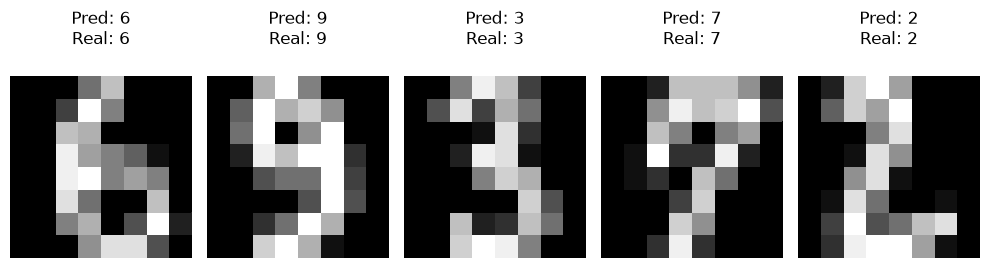

In [25]:
# 1. Predict on the whole test set
y_predicted = model.predict(X_test)

# 2. Pick the first 5 samples from X_test to visualize
fig, axes = plt.subplots(1, 5, figsize=(10, 3))

for i in range(5):
    # Reshape the 64 features back to an 8x8 image
    sample_image = X_test.iloc[i].values.reshape(8, 8)
    axes[i].matshow(sample_image, cmap='gray')
    axes[i].set_title(f"Pred: {y_predicted[i]}\nReal: {y_test.iloc[i]}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

The 10×10 Multiclass Confusion Matrix Heatmap

Since we have 10 digits (0 to 9), a simple print statement makes a messy 10×10
grid. A Seaborn Heatmap lets you see immediately which digits the model got right (diagonal) and where it got confused!

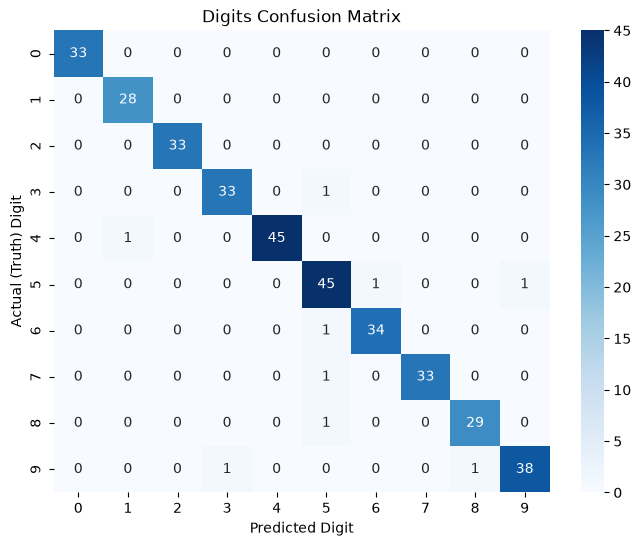

In [26]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, y_predicted)

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual (Truth) Digit')
plt.title('Digits Confusion Matrix')
plt.show()

**Find and Display the Exact Images the Model Got Wrong!**

Total mistakes: 9 out of 360


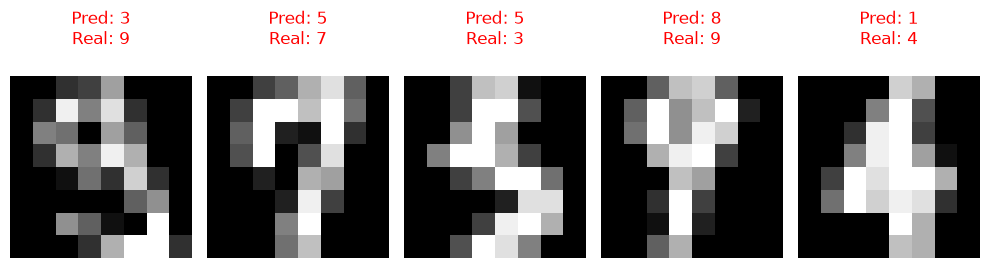

In [27]:
# 1. Find indices where prediction != actual
misclassified_idx = []
for idx in range(len(y_test)):
    if y_predicted[idx] != y_test.iloc[idx]:
        misclassified_idx.append(idx)

print(f"Total mistakes: {len(misclassified_idx)} out of {len(y_test)}")

# 2. Plot the first few mistaken digits
fig, axes = plt.subplots(1, min(5, len(misclassified_idx)), figsize=(10, 3))

for plot_idx, test_idx in enumerate(misclassified_idx[:5]):
    img = X_test.iloc[test_idx].values.reshape(8, 8)
    axes[plot_idx].matshow(img, cmap='gray')
    axes[plot_idx].set_title(f"Pred: {y_predicted[test_idx]}\nReal: {y_test.iloc[test_idx]}", color='red')
    axes[plot_idx].axis('off')

plt.tight_layout()
plt.show()

**Classification Report & Save the Multiclass Model**

In [28]:
from sklearn.metrics import classification_report
import joblib

# 1. Print detailed report per digit (0 to 9)
print("Classification Report per Digit:")
print(classification_report(y_test, y_predicted))

# 2. Save the trained model for future use
joblib.dump(model, 'digits_logistic_model.pkl')
print("Model saved successfully as 'digits_logistic_model.pkl'!")

Classification Report per Digit:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.97      1.00      0.98        28
           2       1.00      1.00      1.00        33
           3       0.97      0.97      0.97        34
           4       1.00      0.98      0.99        46
           5       0.92      0.96      0.94        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       0.97      0.97      0.97        30
           9       0.97      0.95      0.96        40

    accuracy                           0.97       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.97      0.98       360

Model saved successfully as 'digits_logistic_model.pkl'!


#### Re use Model

c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


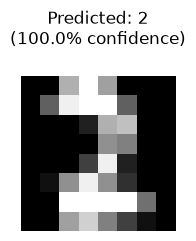

In [33]:
import joblib
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the saved model
model = joblib.load('digits_logistic_model.pkl')

def predict_digit(pixel_array):
    """
    Takes 64 pixel values (or an 8x8 image), predicts the digit,
    and prints prediction with probability confidence.
    """
    pixel_array = np.array(pixel_array).reshape(1, -1)
    
    # Predict digit and class probabilities
    prediction = model.predict(pixel_array)[0]
    probabilities = model.predict_proba(pixel_array)[0]
    confidence = probabilities[prediction] * 100
    
    # Visualize the digit
    plt.figure(figsize=(2, 2))
    plt.matshow(pixel_array.reshape(8, 8), cmap='gray', fignum=1)
    plt.title(f"Predicted: {prediction}\n({confidence:.1f}% confidence)")
    plt.axis('off')
    plt.show()
    
    return prediction, confidence

# --- Example: Test it with sample #15 from X_test ---
test_sample = X_test.iloc[15].values
predicted_num, conf = predict_digit(test_sample)